# 02C · MMM v2: the model, corrected by the experiment

**What changes from v1, simply:** v1 had to guess each channel's effect from history alone, and its
ranges were wide. We have since run a real experiment on quick-commerce (QC) ads (notebook 03B:
₹1.11 back per ₹1, 90% CI 1.06–1.15). MMM v2 is told that result, so the model must agree with it,
and it now sees all 104 weeks.

**Set-up (v2):** national weekly data, fit on weeks 1–96, weeks 97–104 kept aside to test forecasts.
Same channels, priors and controls as v1, so any change comes from the new data and the experiment.

**How the experiment enters the model (lift test calibration):**
- The test switched QC ads in Bengaluru + Hyderabad from full spend to **zero**. So it measured the
  *average* return of all QC spend in those cities: ₹1.11 per ₹1.
- The model is national. The two cities are treated as representative, so the result is stated as:
  "switching QC ads fully off nationally (from current weekly spend x to 0) would lose 1.11 × x per week".
- A first attempt entered the test as a small cut at the top of the national curve. That asks a
  different question (the return of the *last* rupees, not all of them), so it was corrected.
- Uncertainty is **4× the test's own standard error**, scaled up the same way. That matches the design's
  stress case: real markets are noisier than this data, and the 2-city-to-national step adds error.

**Priors (what the model assumes before seeing data), one line each:**
- Adstock decay α ~ Beta(1, 3): most ads fade within weeks; long memory must be shown by the data.
- Half-saturation κ ~ Gamma(mean 0.6, sd 0.4) on spend scaled to its maximum: channels are usually run
  somewhere around half of their peak level, and κ cannot sit at zero.
- Curve shape s ~ Gamma(mean 1.5, sd 0.7): between a plain diminishing curve (s ≈ 1) and an S-curve (s ≈ 2–3).
- Maximum effect β ~ HalfNormal(0.5) on revenue scaled to its maximum: no single channel can plausibly
  drive more than about half of peak weekly revenue on its own.
- The same priors for every channel, so no channel is favoured before seeing the data.
- Controls: list price, festive weeks, temperature, competitor pressure, a linear trend (dark-store count is left out:
  notebook 02A found it nearly identical to the trend, VIF 115, which confuses the sampler),
  **the week after a promotion** (the audit found a dip there, so promotions partly pull sales forward),
  and yearly seasonality (2 Fourier pairs).

In [ ]:
# Colab set-up: run this first (skipped automatically outside Colab)
import sys, os
if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/anvesha2402/prakriti-growth-measurement.git"   # change if your repo differs
    if not os.path.exists("/content/repo"):
        get_ipython().system(f"git clone {REPO_URL} /content/repo")
    os.chdir("/content/repo")
    get_ipython().system("pip install -q 'pymc-marketing==1.1.*' statsmodels h5netcdf")


In [1]:
import os, sys, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else "src")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arviz as az
from pymc_marketing.mmm import MMM, GeometricAdstock, HillSaturation
from pymc_extras.prior import Prior
import json
from common import load, national, CHANNELS, LABEL, COLOR, INK, INK2, NEUTRAL, style, save, ROOT, FULL

style()
QUICK = os.environ.get("QUICK") == "1"          # quick smoke test; real run uses full sampling
w, p = load(FULL)
nat = national(w).reset_index()

df = pd.DataFrame({"date": nat["week_start"]})
for c in CHANNELS:
    df[c] = nat[f"spend_{c}_lakh"]
CONTROLS = ["price_index", "festive_flag", "temp_c", "competitor_index"]   # dark stores dropped: VIF 115 with the trend (02A), same information twice
for c in CONTROLS:
    df[c] = (nat[c] - nat[c].mean()) / nat[c].std()
df["trend"] = (np.arange(len(df)) - len(df) / 2) / len(df)
df["post_promo"] = ((nat["promo_flag"].shift(1) == 1) & (nat["promo_flag"] == 0)).astype(float)
y = nat["revenue_lakh"].rename("revenue")
train = nat["week"] <= 96
test = ~train
print(f"Training weeks: {train.sum()}, holdout weeks: {test.sum()}")

Training weeks: 96, holdout weeks: 8


## 1. Fit the model

In [2]:
mmm = MMM(date_column="date", channel_columns=CHANNELS, target_column="revenue",
          adstock=GeometricAdstock(l_max=24),
          saturation=HillSaturation(priors={
              "kappa": Prior("Gamma", mu=0.6, sigma=0.4, dims="channel"),
              "slope": Prior("Gamma", mu=1.5, sigma=0.7, dims="channel"),
              "beta": Prior("HalfNormal", sigma=0.5, dims="channel")}),
          control_columns=CONTROLS + ["trend", "post_promo"], yearly_seasonality=2)
mmm.build_model(df[train], y[train])
exp = json.loads((ROOT / "model" / "experiment_result.json").read_text())
test_wk = nat["week"].between(*exp["weeks"])
withheld_wk = exp["spend_withheld_lakh"] / 8
x_now = float(nat.loc[test_wk, "spend_qc_ads_lakh"].mean() + withheld_wk)   # national weekly QC spend had there been no pause
scale_up = x_now / withheld_wk                                              # 2 test cities -> whole country
lift = pd.DataFrame([{
    "channel": "qc_ads",
    "x": x_now,
    "delta_x": -x_now,                                                     # full switch-off, as in the test cities
    "delta_y": -exp["roi"] * x_now,                                        # average return measured by the test
    "sigma": 4 * exp["se_lakh_per_week"] * scale_up,                       # stress-case uncertainty, scaled the same way
}])
print(lift.round(3).to_string(index=False))
mmm.add_lift_test_measurements(lift)
t0 = time.time()
mmm.fit(df[train], y[train],
        draws=200 if QUICK else 2000, tune=200 if QUICK else 2000,
        chains=2 if QUICK else 4, target_accept=0.99, random_seed=2402, progressbar=False,
        nuts_sampler="nutpie")      # fast Rust sampler; same algorithm (NUTS), much quicker
print(f"Sampling time: {time.time() - t0:.0f} s")
post = mmm.idata.posterior

channel      x  delta_x  delta_y  sigma
 qc_ads 17.449  -17.449  -19.306  2.009


NUTS[nutpie]: [saturation_slope, adstock_alpha, saturation_kappa, saturation_beta, gamma_fourier, gamma_control, y_sigma, intercept_contribution]


Sampling time: 1362 s


## 2. Diagnostics: can we trust the sampler?
- **R-hat < 1.01:** the 4 independent chains agree.
- **ESS > 400:** enough independent samples.
- **0 divergences:** the sampler never got stuck.

In [3]:
params = ["adstock_alpha", "saturation_kappa", "saturation_slope", "saturation_beta",
          "gamma_control", "gamma_fourier", "intercept_contribution", "y_sigma"]
summ = az.summary(mmm.idata, var_names=params, kind="diagnostics")
div = int(mmm.idata.sample_stats["diverging"].sum())
diag = pd.Series({"max R-hat": summ["r_hat"].max(), "min bulk ESS": summ["ess_bulk"].min(),
                  "min tail ESS": summ["ess_tail"].min(), "divergences": div})
diag["PASS"] = bool(diag["max R-hat"] < 1.01 and diag["min bulk ESS"] > 400 and div == 0)
print(diag.to_string())

max R-hat         1.011726
min bulk ESS    432.564101
min tail ESS    706.767453
divergences            0.0
PASS                 False


## 3. Does it forecast unseen weeks? (holdout weeks 97–104)

Sampling: [lift_measurements, y]


Sampling: [lift_measurements, y]


In-sample MAPE: 1.0%   |   Holdout MAPE (weeks 97–104): 3.2%   |   holdout weeks inside 90% band: 88%


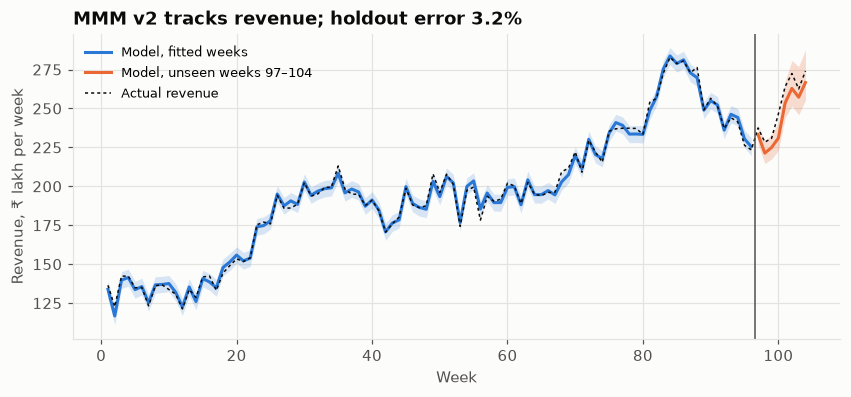

In [4]:
pp_in = mmm.sample_posterior_predictive(df[train], extend_idata=False, progressbar=False)
pp_out = mmm.sample_posterior_predictive(df[test], include_last_observations=True, extend_idata=False,
                                         progressbar=False)

def to_rupees(pp):
    var = "y_original_scale" if "y_original_scale" in pp else "y"
    arr = pp[var]
    other = [d for d in arr.dims if d not in ("date",)]
    m = arr.mean(other).values
    lo, hi = arr.quantile(0.05, other).values, arr.quantile(0.95, other).values
    scale = 1.0 if var == "y_original_scale" or m.mean() > 5 else float(mmm.idata.constant_data["target_scale"])
    return m * scale, lo * scale, hi * scale

fit_m, fit_lo, fit_hi = to_rupees(pp_in)
out_m, out_lo, out_hi = to_rupees(pp_out)
mape_hold = float(np.mean(np.abs(out_m - y[test].values) / y[test].values))
mape_in = float(np.mean(np.abs(fit_m - y[train].values) / y[train].values))
cover = float(np.mean((y[test].values >= out_lo) & (y[test].values <= out_hi)))
print(f"In-sample MAPE: {mape_in:.1%}   |   Holdout MAPE (weeks 97–104): {mape_hold:.1%}   "
      f"|   holdout weeks inside 90% band: {cover:.0%}")

fig, ax = plt.subplots(figsize=(9, 3.6))
wk = nat["week"].values
ax.fill_between(wk[train], fit_lo, fit_hi, color="#2a78d6", alpha=0.18, lw=0)
ax.fill_between(wk[test], out_lo, out_hi, color="#eb6834", alpha=0.22, lw=0)
ax.plot(wk[train], fit_m, color="#2a78d6", label="Model, fitted weeks")
ax.plot(wk[test], out_m, color="#eb6834", label="Model, unseen weeks 97–104")
ax.plot(wk, y.values, color=INK, lw=1, ls=(0, (2, 2)), label="Actual revenue")
ax.axvline(96.5, color=INK2, lw=1)
ax.set_xlabel("Week"); ax.set_ylabel("Revenue, ₹ lakh per week")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax.set_title(f"MMM v2 tracks revenue; holdout error {mape_hold:.1%}")
save(fig, "02C_fit_and_holdout"); plt.show()

## 4. Rebuild each channel's effect from the model, draw by draw
We recompute adstock + Hill ourselves from the posterior samples. This lets us ask "what if spend
were different?" cheaply, for ROI, marginal ROI and response curves. Check: the rebuilt effect
must match the model's own channel contribution.

In [5]:
cd = mmm.idata.constant_data
target_scale = float(cd["target_scale"])
ch_scale = cd["channel_scale"].to_series().reindex(CHANNELS).values
L_MAX = 24

def stack(name):
    return post[name].stack(sample=("chain", "draw")).transpose("sample", ...).values

alpha, kappa = stack("adstock_alpha"), stack("saturation_kappa")
slope, beta = stack("saturation_slope"), stack("saturation_beta")
X_train = df.loc[train, CHANNELS].values                 # weeks x channels (₹ lakh)

def contribution(X, ci, mult=1.0, weeks_mask=None):
    """Weekly contribution of channel ci (₹ lakh), per posterior draw: shape (draws, weeks)."""
    x = X[:, ci].copy()
    if weeks_mask is not None:
        x[weeks_mask] *= mult
    else:
        x *= mult
    xs = x / ch_scale[ci]
    a = alpha[:, ci][:, None] ** np.arange(L_MAX)[None, :]
    a = a / a.sum(1, keepdims=True)
    T = len(xs)
    ad = np.zeros((len(alpha), T))
    for lag in range(L_MAX):
        ad[:, lag:] += a[:, [lag]] * xs[None, :T - lag]
    s, k = slope[:, ci][:, None], kappa[:, ci][:, None]
    h = ad**s / (ad**s + k**s)
    return beta[:, ci][:, None] * h * target_scale

model_contrib = post["channel_contribution"].stack(sample=("chain", "draw")).transpose("sample", "date", "channel")
check = max(abs(contribution(X_train, i).mean(0).sum() - float(model_contrib.isel(channel=i).mean("sample").sum()) * target_scale)
            / (float(model_contrib.isel(channel=i).mean("sample").sum()) * target_scale) for i in range(len(CHANNELS)))
print(f"Rebuild check, worst channel gap vs model: {check:.2%}")

Rebuild check, worst channel gap vs model: 0.00%


## 5. ROI and marginal ROI by channel
- **ROI:** incremental revenue ÷ spend over weeks 1–96 (average return).
- **Marginal ROI (mROI):** extra revenue from the *next* ₹1, measured by raising the last 26 weeks'
  spend by 1%. This is the number a budget cut should use.

In [6]:
spend_tot = X_train.sum(0)
recent = np.zeros(len(X_train), bool); recent[-26:] = True
rows = []
for i, c in enumerate(CHANNELS):
    base = contribution(X_train, i)
    roi = base.sum(1) / spend_tot[i]
    bumped = contribution(X_train, i, 1.01, recent)
    mroi = (bumped - base).sum(1) / (0.01 * X_train[recent, i].sum())
    rows.append(dict(channel=LABEL[c], key=c, roi=np.median(roi), roi_lo=np.quantile(roi, .05), roi_hi=np.quantile(roi, .95),
                     mroi=np.median(mroi), mroi_lo=np.quantile(mroi, .05), mroi_hi=np.quantile(mroi, .95),
                     contribution_cr=np.median(base.sum(1)) / 100, spend_cr=spend_tot[i] / 100))
roi_tbl = pd.DataFrame(rows).set_index("channel")
# Trade promotions: net out the post-promotion dip the model found (pull-forward)
cc = post["control_contribution"].stack(sample=("chain", "draw")).transpose("sample", ...)
dip = cc.sel(control="post_promo").sum("date").values * target_scale          # ₹ lakh, per draw (negative = dip)
ti = CHANNELS.index("trade_promo")
gross = contribution(X_train, ti).sum(1)
net_roi = (gross + dip) / spend_tot[ti]
print(f"Post-promotion dip found by the model: ₹{np.median(dip)/100:.2f} Cr over weeks 1–96 "
      f"(90%: {np.quantile(dip,.05)/100:.2f} to {np.quantile(dip,.95)/100:.2f})")
roi_tbl.loc["Trade promotions", ["roi_gross_before_dip"]] = np.median(gross / spend_tot[ti])
roi_tbl.loc["Trade promotions", ["roi", "roi_lo", "roi_hi"]] = [np.median(net_roi), np.quantile(net_roi, .05), np.quantile(net_roi, .95)]
roi_tbl.loc["Trade promotions", "contribution_cr"] = np.median(gross + dip) / 100
plat = (p[p.week <= 96].groupby("channel").apply(lambda d: d.reported_revenue_lakh.sum() / d.spend_lakh.sum(), include_groups=False))
roi_tbl["platform_roas"] = roi_tbl["key"].map(plat)
roi_tbl["interval_width"] = roi_tbl["roi_hi"] - roi_tbl["roi_lo"]
roi_tbl["rupees_uncertain_cr"] = roi_tbl["interval_width"] * roi_tbl["spend_cr"]   # how much money the uncertainty puts at risk
# How tangled are Meta and YouTube? Negative correlation between their ROI draws = the model trades one for the other.
roi_draws = {c: contribution(X_train, i).sum(1) / spend_tot[i] for i, c in enumerate(CHANNELS)}
tangle = np.corrcoef(roi_draws["meta"], roi_draws["youtube"])[0, 1]
print(f"Correlation between Meta and YouTube ROI draws: {tangle:+.2f} (strongly negative = model cannot separate them)")
roi_tbl.drop(columns="key").round(2)

Post-promotion dip found by the model: ₹0.14 Cr over weeks 1–96 (90%: -0.39 to 0.59)


Correlation between Meta and YouTube ROI draws: +0.03 (strongly negative = model cannot separate them)


,roi,roi_lo,roi_hi,mroi,mroi_lo,mroi_hi,contribution_cr,spend_cr,roi_gross_before_dip,platform_roas,interval_width,rupees_uncertain_cr
channel,,,,,,,,,,,,
Meta,0.08,0.01,1.14,0.03,0.00,0.13,1.11,13.46,NaN,7.35,1.14,15.30
Quick-commerce ads,1.26,0.49,1.63,0.45,0.19,2.54,14.49,11.52,NaN,7.18,1.14,13.16
Google Search,0.93,0.61,1.42,4.59,2.55,5.86,7.38,7.91,NaN,4.85,0.81,6.40
Trade promotions,2.45,1.30,6.25,0.70,0.55,0.81,15.50,6.31,2.43,2.60,4.95,31.27
YouTube,1.33,1.06,1.64,3.23,2.72,3.74,10.39,7.83,NaN,2.53,0.58,4.55
Influencers,1.83,1.07,2.77,3.40,2.06,4.81,9.49,5.19,NaN,4.79,1.70,8.82


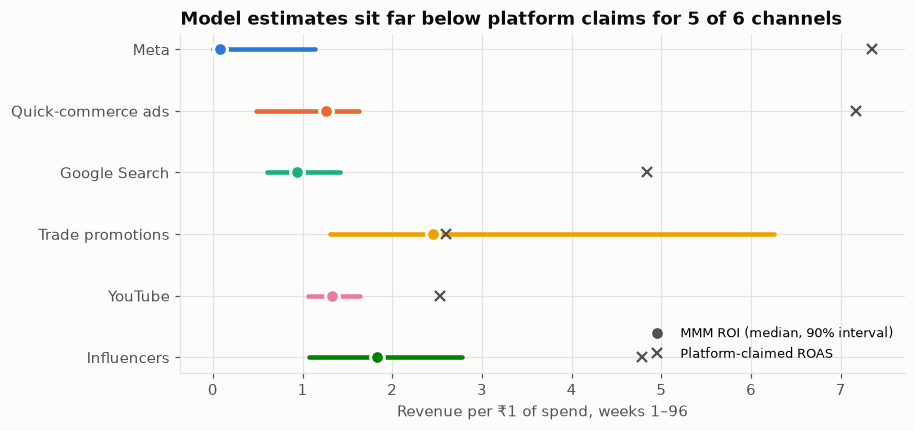

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4))
yy = np.arange(len(roi_tbl))
for j, (name, r) in enumerate(roi_tbl.iterrows()):
    ax.plot([r.roi_lo, r.roi_hi], [j, j], color=COLOR[r.key], lw=3, solid_capstyle="round")
    ax.plot(r.roi, j, "o", color=COLOR[r.key], ms=9, mec="#fcfcfb", mew=2)
    ax.plot(r.platform_roas, j, marker="x", color=INK2, ms=7, mew=1.5)
ax.plot([], [], "o", color=INK2, label="MMM ROI (median, 90% interval)")
ax.plot([], [], "x", color=INK2, ms=7, mew=1.5, label="Platform-claimed ROAS")
ax.set_yticks(yy, roi_tbl.index); ax.invert_yaxis()
ax.set_xlabel("Revenue per ₹1 of spend, weeks 1–96")
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
ax.set_title("Model estimates sit far below platform claims for 5 of 6 channels")
save(fig, "02C_roi_vs_platform"); plt.show()

## 6. Response curves: where is each channel on its tiredness curve?
Each curve shows total incremental revenue if the whole channel's spend were scaled from 0× to 2×.
The dot marks today's spend. A flat curve at the dot = saturated; steep = room to grow.

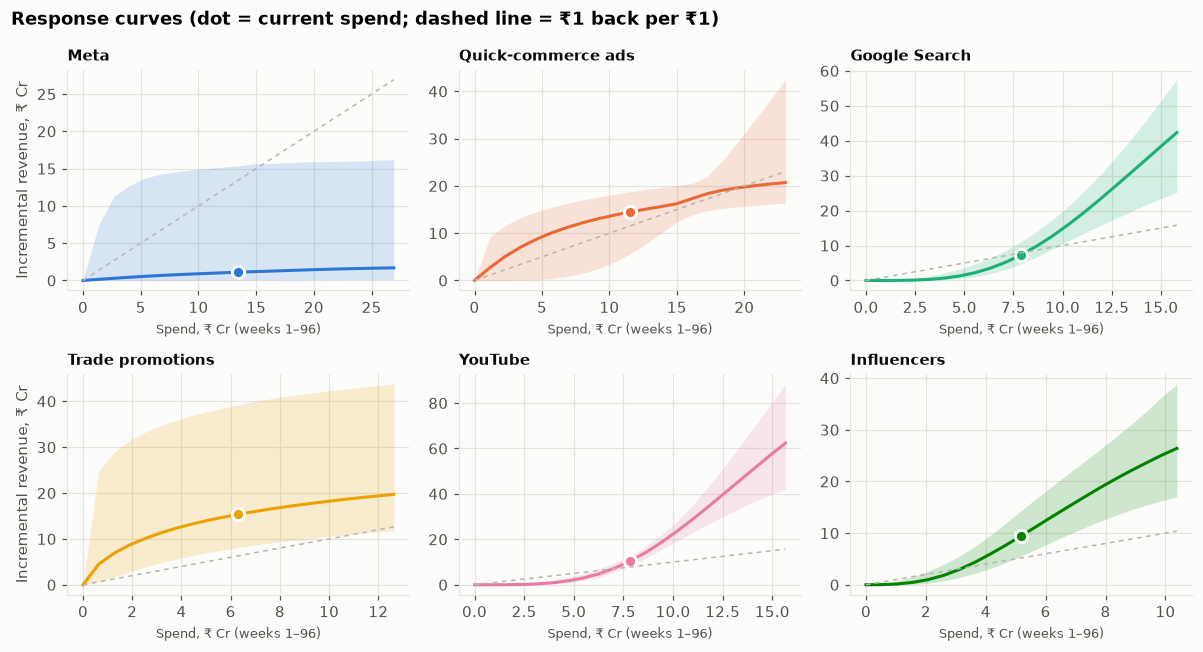

In [8]:
mults = np.linspace(0, 2, 21)
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharey=False)
curves = {}
for i, (c, ax) in enumerate(zip(CHANNELS, axes.ravel())):
    vals = np.array([contribution(X_train, i, m).sum(1) for m in mults]) / 100      # (mults, draws) ₹ Cr
    med, lo, hi = np.median(vals, 1), np.quantile(vals, .05, 1), np.quantile(vals, .95, 1)
    curves[c] = pd.DataFrame({"spend_multiple": mults, "spend_cr": mults * spend_tot[i] / 100,
                              "contribution_cr": med, "lo": lo, "hi": hi})
    xs = mults * spend_tot[i] / 100
    ax.fill_between(xs, lo, hi, color=COLOR[c], alpha=0.18, lw=0)
    ax.plot(xs, med, color=COLOR[c])
    ax.plot(spend_tot[i] / 100, np.interp(1, mults, med), "o", color=COLOR[c], ms=8, mec="#fcfcfb", mew=2)
    ax.plot(xs, xs, color=NEUTRAL, lw=1, ls=(0, (3, 3)))
    ax.set_title(LABEL[c], fontsize=10)
    ax.set_xlabel("Spend, ₹ Cr (weeks 1–96)", fontsize=8.5)
axes[0, 0].set_ylabel("Incremental revenue, ₹ Cr"); axes[1, 0].set_ylabel("Incremental revenue, ₹ Cr")
fig.suptitle("Response curves (dot = current spend; dashed line = ₹1 back per ₹1)", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "02C_response_curves"); plt.show()

## 7. Adstock: how long does each channel's effect last?

In [9]:
hl = np.log(0.5) / np.log(np.clip(alpha, 1e-6, 0.999999))
ad_tbl = pd.DataFrame({"half-life median (weeks)": np.median(hl, 0), "5%": np.quantile(hl, .05, 0),
                       "95%": np.quantile(hl, .95, 0)}, index=[LABEL[c] for c in CHANNELS])
ad_tbl.round(2)

,half-life median (weeks),5%,95%
Meta,0.42,0.17,1.32
Quick-commerce ads,0.48,0.18,3.59
Google Search,1.53,0.69,2.15
Trade promotions,0.20,0.11,0.30
YouTube,5.41,3.88,7.23
Influencers,3.08,1.85,5.15


## 8. Save outputs for later steps (optimiser, app, copilot)

In [10]:
out_dir = ROOT / "model"; out_dir.mkdir(exist_ok=True)
roi_tbl.drop(columns="key").to_csv(out_dir / "mmm_v2_roi.csv")
pd.concat({LABEL[c]: d for c, d in curves.items()}).to_csv(out_dir / "mmm_v2_response_curves.csv")
pd.DataFrame([diag]).to_csv(out_dir / "mmm_v2_diagnostics.csv", index=False)
pd.DataFrame({"alpha": [*alpha.T], }).head(0)
np.savez_compressed(out_dir / "mmm_v2_posterior_params.npz", alpha=alpha, kappa=kappa, slope=slope, beta=beta,
                    channel_scale=ch_scale, target_scale=target_scale, channels=np.array(CHANNELS))
if not QUICK:
    try:
        mmm.save(str(out_dir / "mmm_v2.nc"))   # large file: kept on Drive, not GitHub
    except Exception as e:
        print("Model file not saved (needs h5netcdf or netCDF4):", e)
print("Saved:", *sorted(p.name for p in out_dir.glob("mmm_v2*")))

Saved: mmm_v2.nc mmm_v2_FROZEN.json mmm_v2_diagnostics.csv mmm_v2_posterior_params.npz mmm_v2_response_curves.csv mmm_v2_roi.csv


## 9. What did the experiment change? (v1 → v2)

                    v1 ROI     v1 90%  v2 ROI     v2 90%  interval width v1  interval width v2  narrower by
channel                                                                                                    
Meta                  0.09    0.0–1.4    0.08  0.01–1.14               1.40               1.14         0.19
Quick-commerce ads    0.71  0.14–3.49    1.26  0.49–1.63               3.35               1.14         0.66
Google Search         1.49  0.79–4.63    0.93  0.61–1.42               3.83               0.81         0.79
Trade promotions      2.72  1.41–7.03    2.45   1.3–6.25               5.62               4.95         0.12
YouTube               1.25   0.95–1.6    1.33  1.06–1.64               0.65               0.58         0.10
Influencers           1.02  0.41–2.99    1.83  1.07–2.77               2.58               1.70         0.34

QC ads: v1 0.71 (0.14–3.49) → v2 1.26 (0.49–1.63); experiment said 1.11 (1.06–1.15). Interval 66% narrower.


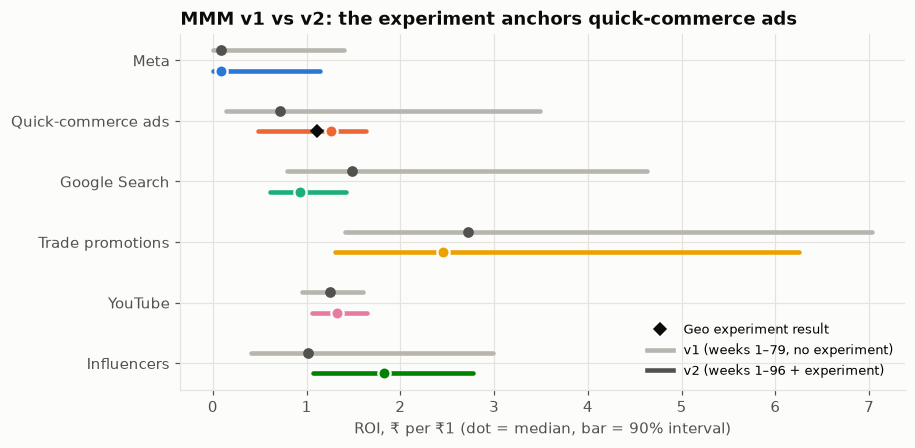

In [11]:
v1 = pd.read_csv(out_dir / "mmm_v1_roi.csv").set_index("channel")
v2 = roi_tbl
cmp_ = pd.DataFrame({"v1 ROI": v1.roi, "v1 90%": v1.roi_lo.round(2).astype(str) + "–" + v1.roi_hi.round(2).astype(str),
                     "v2 ROI": v2.roi, "v2 90%": v2.roi_lo.round(2).astype(str) + "–" + v2.roi_hi.round(2).astype(str),
                     "interval width v1": v1.interval_width, "interval width v2": v2.interval_width})
cmp_["narrower by"] = 1 - cmp_["interval width v2"] / cmp_["interval width v1"]
print(cmp_.round(2).to_string())
qc = cmp_.loc["Quick-commerce ads"]
print(f"\nQC ads: v1 {qc['v1 ROI']:.2f} ({qc['v1 90%']}) → v2 {qc['v2 ROI']:.2f} ({qc['v2 90%']}); "
      f"experiment said {exp['roi']:.2f} ({exp['roi_ci90'][0]:.2f}–{exp['roi_ci90'][1]:.2f}). "
      f"Interval {qc['narrower by']:.0%} narrower.")

fig, ax = plt.subplots(figsize=(8.5, 4.2))
for j, (name, r) in enumerate(cmp_.iterrows()):
    key = [k for k, v in LABEL.items() if v == name][0]
    ax.plot([v1.loc[name, "roi_lo"], v1.loc[name, "roi_hi"]], [j - 0.17, j - 0.17], color=NEUTRAL, lw=3, solid_capstyle="round")
    ax.plot(v1.loc[name, "roi"], j - 0.17, "o", color=INK2, ms=6)
    ax.plot([v2.loc[name, "roi_lo"], v2.loc[name, "roi_hi"]], [j + 0.17, j + 0.17], color=COLOR[key], lw=3, solid_capstyle="round")
    ax.plot(v2.loc[name, "roi"], j + 0.17, "o", color=COLOR[key], ms=8, mec="#fcfcfb", mew=1.5)
jq = list(cmp_.index).index("Quick-commerce ads")
ax.plot(exp["roi"], jq + 0.17, marker="D", color=INK, ms=6, ls="none", label="Geo experiment result")
ax.plot([], [], color=NEUTRAL, lw=3, label="v1 (weeks 1–79, no experiment)")
ax.plot([], [], color=INK2, lw=3, label="v2 (weeks 1–96 + experiment)")
ax.set_yticks(range(len(cmp_)), cmp_.index); ax.invert_yaxis()
ax.set_xlabel("ROI, ₹ per ₹1 (dot = median, bar = 90% interval)")
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
ax.set_title("MMM v1 vs v2: the experiment anchors quick-commerce ads")
save(fig, "02C_v1_vs_v2"); plt.show()

## 10. Freeze v2 for grading
From here on v2 is not refitted. Its numbers are what gets graded against the sealed answer key.

In [12]:
import hashlib
frozen = {f.name: hashlib.sha256(f.read_bytes()).hexdigest() for f in sorted(out_dir.glob("mmm_v2_*")) if f.suffix != ".nc" and "FROZEN" not in f.name}
(out_dir / "mmm_v2_FROZEN.json").write_text(json.dumps({"frozen_files": frozen}, indent=1))
print(json.dumps(frozen, indent=1))

{
 "mmm_v2_diagnostics.csv": "2eddd0f9d13c9f9d7101303655971a912dad2769e361a5a7fa79f34ac5feeee8",
 "mmm_v2_posterior_params.npz": "7a9dc8f2ef266efdfafed3821a692f87071934a24da97ef56951be13ec749afa",
 "mmm_v2_response_curves.csv": "d67a74d09a1aaf1ac89d395045cfb0f3d08aacfb7c88f4742467037a316200fd",
 "mmm_v2_roi.csv": "1a8d4e039a2682a9edc09eadb04e7d1324051e601a998699a234268feca75b82"
}


## 10b. Have the decision numbers converged?
Some model *parameters* can wander along a ridge without changing what matters. Here the experiment
fixes QC ads' total effect but not how it splits between curve height and shape. So we also check
R-hat on the quantity decisions use: **ROI per channel**.

In [13]:
from roi_convergence import roi_rhat
conv = roi_rhat(out_dir / "mmm_v2_posterior_params.npz", X_train, CHANNELS, LABEL, chains=4)
print(conv.round(3).to_string())
param_pass = bool(diag["max R-hat"] < 1.01 and diag["min bulk ESS"] > 400 and diag["divergences"] == 0)
roi_pass = conv.index[conv.r_hat < 1.01].tolist()
STATUS = "PASS" if param_pass else ("BORDERLINE" if diag["max R-hat"] < 1.02 and diag["divergences"] == 0 else "FAIL")
print(f"Parameter diagnostics: {STATUS} (max R-hat {diag['max R-hat']:.4f}, min ESS {diag['min bulk ESS']:.0f}, "
      f"{int(diag['divergences'])} divergences). ROI converged (R-hat < 1.01) for {len(roi_pass)} of {len(conv)} channels.")
conv.to_csv(out_dir / "mmm_v2_roi_convergence.csv")

                    roi_median  r_hat  ess_bulk
channel                                        
Meta                     0.082  1.002  2024.237
Quick-commerce ads       1.257  1.011   437.530
Google Search            0.933  1.001  3737.196
Trade promotions         2.434  1.004  2405.883
YouTube                  1.327  1.000  7714.556
Influencers              1.828  1.002  1484.007
Parameter diagnostics: BORDERLINE (max R-hat 1.0117, min ESS 433, 0 divergences). ROI converged (R-hat < 1.01) for 5 of 6 channels.


## 11. So what (for the CFO)

In [14]:
r = roi_tbl.sort_values("roi", ascending=False)
room = roi_tbl.sort_values("mroi", ascending=False)
sat = roi_tbl.sort_values("mroi")
print("SO WHAT")
print("1. Ranking by true average return (v2): " + ", ".join(f"{n} {v:.2f}" for n, v in r.roi.items()) + " (₹ per ₹1).")
print(f"2. Where the next rupee works hardest: {room.index[0]} (mROI {room.mroi.iloc[0]:.2f}), {room.index[1]} ({room.mroi.iloc[1]:.2f}). "
      f"Where it works least: {sat.index[0]} ({sat.mroi.iloc[0]:.2f}), {sat.index[1]} ({sat.mroi.iloc[1]:.2f}).")
print(f"3. The experiment moved QC ads from {qc['v1 ROI']:.2f} to {qc['v2 ROI']:.2f} and narrowed its range by {qc['narrower by']:.0%}.")
not_conv = [c for c in conv.index if c not in roi_pass]
print(f"4. Trust: diagnostics {STATUS}; holdout error {mape_hold:.1%}; ROI converged for {len(roi_pass)} of 6 channels"
      + (f" ({', '.join(not_conv)} borderline at R-hat {conv.loc[not_conv, 'r_hat'].max():.3f}; for QC ads the experiment's direct "
         f"measurement {exp['roi']:.2f} ({exp['roi_ci90'][0]:.2f}–{exp['roi_ci90'][1]:.2f}) is the anchor)" if not_conv else "")
      + ". v2 is now frozen for grading and the optimiser.")

SO WHAT
1. Ranking by true average return (v2): Trade promotions 2.45, Influencers 1.83, YouTube 1.33, Quick-commerce ads 1.26, Google Search 0.93, Meta 0.08 (₹ per ₹1).
2. Where the next rupee works hardest: Google Search (mROI 4.59), Influencers (3.40). Where it works least: Meta (0.03), Quick-commerce ads (0.45).
3. The experiment moved QC ads from 0.71 to 1.26 and narrowed its range by 66%.
4. Trust: diagnostics BORDERLINE; holdout error 3.2%; ROI converged for 5 of 6 channels (Quick-commerce ads borderline at R-hat 1.011; for QC ads the experiment's direct measurement 1.11 (1.06–1.15) is the anchor). v2 is now frozen for grading and the optimiser.
